In [1]:
import random
import pandas as pd
import numpy as np
from transformers import BertTokenizer, BertModel
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import matplotlib.cm as cm 
from sklearn.mixture import GaussianMixture
from sklearn.cluster import SpectralClustering
import shap
import torch

c:\Users\ias-d\anaconda3\envs\NLP\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def load_data(dataset_name, api):
	file_paths = {
		'gpt': f'../../output/API_classification/gpt/{dataset_name}_aggregate/gpt_{dataset_name}_aggregate.csv',
		'amazon': f'../../output/API_classification/amazon/{dataset_name}_aggregate/amazon_{dataset_name}_aggregate.csv',
		'google': f'../../output/API_classification/google/{dataset_name}_aggregate/google_{dataset_name}_aggregate.csv',
		'microsoft': f'../../output/API_classification/microsoft/{dataset_name}_aggregate/microsoft_{dataset_name}_aggregate.csv'
		}
	return pd.read_csv(file_paths[api])

In [3]:
def get_mislabeled_data(dataset_name, api, label_difference, should_remove_stopwords=False):
	file = load_data(dataset_name, api)
	index = file.index[file['predicted_label'] - file['true_label'] == label_difference].tolist()  # find indexes for mismatches
	mislabeled_data = file.loc[index].reset_index(drop=True)  # reset index for the new DataFrame
	ids_column = 'id' if api == 'microsoft' else 'ids'
	return mislabeled_data[[ids_column, 'text', 'score', 'predicted_label', 'true_label']]

In [5]:
fp = [get_mislabeled_data('toxigen', api, 1) for api in ['gpt', 'microsoft', 'amazon', 'google']]
fn = [get_mislabeled_data('toxigen', api, -1) for api in ['gpt', 'microsoft', 'amazon', 'google']]

# find for all APIs the 

In [14]:
len(fn[2])

2039

In [260]:
print(fp[3].head())

       ids                                               text     score  \
0   HX6563  <user> here is how to end sanctions on syria <...  0.990868   
1   HX8194  <user> daniel did you dress up as arabs and bo...  0.867188   
2  HX11903  <user> <user> nazi is just a anglicised word f...  0.813333   
3   HX3249  <user> that white kid is why we have active sh...  0.769231   
4   HX2130  <user> oh good so no money for all of the refu...  0.608621   

   predicted_label  true_label  
0                1           0  
1                1           0  
2                1           0  
3                1           0  
4                1           0  


In [248]:
df1 = fp[0]
df2 = fp[1]
df2['ids'] = df2['id']
df3 = fp[2]
df4 = fp[3]


In [229]:
df2

,id,text,score,predicted_label,true_label,ids
0,JS796975,The damage done by Sullivan and the rest of th...,0.988,1,0,JS796975
1,JS307305,"The assumption that the left only ""favors gove...",0.988,1,0,JS307305
2,JS1002737,"Riel_Un-Canadian, how dare you to address some...",0.988,1,0,JS1002737
3,JS578213,That is one of the most ignorant arguments I h...,0.988,1,0,JS578213
4,JS170207,"""epidemic"", you liberty loathing leftist are s...",0.988,1,0,JS170207
...,...,...,...,...,...,...
5098,JS779591,didn't mean to hurt ur feelings eric. I know h...,0.988,1,0,JS779591
5099,JS1432897,It is way better today. Looks like I'll be he...,0.988,1,0,JS1432897
5100,JS1047705,And your documentation? \r\n Blase Cupich beca...,0.988,1,0,JS1047705
5101,JS583372,Not quite correct. The only definition for sex...,0.988,1,0,JS583372


In [251]:
merged_df = df1[['ids', 'predicted_label']].merge(
    df2[['ids', 'predicted_label']], on='ids', suffixes=('_df1', '_df2')).merge(
    df3[['ids', 'predicted_label']], on='ids').merge(
    df4[['ids', 'predicted_label']], on='ids', suffixes=('_df3', '_df4'))

# Step 2: Filter for rows where all APIs made the same false positive (predicted_label = 1, true_label = 0)
false_positive_all = merged_df[(merged_df['predicted_label_df1'] == 1) &
                               (merged_df['predicted_label_df2'] == 1) &
                               (merged_df['predicted_label_df3'] == 1) &  # from df3
                               (merged_df['predicted_label_df4'] == 1)]

# Step 3: Filter for rows where all APIs made the same false negative (predicted_label = 0, true_label = 1)
false_negative_all = merged_df[(merged_df['predicted_label_df1'] == 0) &
                               (merged_df['predicted_label_df2'] == 0) &
                               (merged_df['predicted_label_df3'] == 0) &  # from df3
                               (merged_df['predicted_label_df4'] == 0)]

# Step 4: (Optional) Merge the false positive and false negative results for a complete view
all_false = pd.concat([false_positive_all, false_negative_all])


In [253]:
df = load_data('jigsaw', 'gpt')
df = df[df['ids'].isin(all_false['ids'])]
# save the data
df.to_csv('falsepositives_hatexplain.csv', index=False)

In [197]:
#Load data
out_file_words = f'../../output/API_classification/shap/gpt/toxigen/gpt_toxigen.csv'
shap_words = pd.read_csv(out_file_words, sep = ',')



In [165]:
len(shap_words['shap_values'])

130

In [191]:
def transform_shap(shap_values):
    a = shap_values.split(' ')
    # remove all \n, empty strings and '['
    a = [i.replace('[', '') for i in a]
    a = [i.replace('\n', '') for i in a]
    a = [i.replace(']', '') for i in a]
    a = [i.replace(',', '') for i in a]
    a = [float(i) for i in a if i != '' and i != '[']
    # to numpy array
    a = np.array(a)
    return a

In [196]:
def transform_token(tokens):
    a = tokens.split(' ')
    # remove all \n, empty strings and '['
    a = [i.replace('[', '') for i in a]
    a = [i.replace('\n', '') for i in a]
    a = [i.replace(']', '') for i in a]
    a = [i.replace(',', '') for i in a]
    a = [i.replace("'", '') for i in a]
    a = [i.replace('"', '') for i in a]
    a = [str(i) for i in a if i != '' and i != '[' and i != ',' and i != ']' and i != ', ' and i != ' ']
    return np.array(a)

In [198]:
for i in range(len(shap_words['shap_values'])):
    shap_words['shap_values'].iloc[i] = transform_shap(shap_words['shap_values'].iloc[i])
    shap_words['tokenized'].iloc[i] = transform_token(shap_words['tokenized'].iloc[i])

C:\Users\ias-d\AppData\Local\Temp\ipykernel_33336\2463783718.py:2: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  shap_words['shap_values'].iloc[i] = transform_shap(shap_words['shap_values'].iloc[i])
C:\Users\ias-d\AppData\Local\Temp\ipykerne

In [34]:
import pandas as pd
import numpy as np
import json
import shap

pre = pd.read_csv(f'../../output/API_classification/shap/amazon/toxigen/amazon_toxigen.csv')
pre['tokenized'] = pre['tokenized'].apply(json.loads)
pre['shap_values'] = pre['shap_values'].apply(json.loads)
pre['base_values'] = pre['base_values'].apply(json.loads)
index = pre['id'].index['TG7199' == pre['id']][0]

t = np.array(pre.iloc[index]['tokenized'])
s = np.array(pre.iloc[index]['shap_values'])
b = np.array(pre.iloc[index]['base_values'])
print(s.shape)
print(t.shape)
print(b.shape)
expla = shap.Explanation(s, base_values=b[0], data= t)

shap.plots.text(expla)

(15,)
(15,)
(2,)


In [199]:
print(shap_words)

    Unnamed: 0                                          tokenized  \
0            0  [jews, are, the, most, hated, group, of, peopl...   
1            1  [Muslims, are, the, largest, religious, group,...   
2            2  [Jews, are, the, most, targeted, religious, gr...   
3            3  [My, child, said, Pa, pi, ., Muslims, are, sca...   
4            4  [Islam, is, not, a, race, it, is, a, religion,...   
..         ...                                                ...   
125     TG8107  [so, basically, a, jewish, merchant, will, nev...   
126     TG7438  [It, is, possible, to, change, behavior, of, m...   
127     TG3553  [hispanic, culture, is, often, reduced, to, na...   
128     TG7872  [they, do, not, care, if, you, are, a, good, p...   
129     TG2454  [people, who, are, deaf, or, hard, of, hearing...   

                                           shap_values  
0    [-0.00223754, -0.45697419, -0.20165577, 0.0397...  
1    [-0.00608468, -0.47682616, -0.17734353, 0.0863...  


# Concepts

In [192]:
def concept_cluster(df):
    concept = concepts()
    classes = []
    for key in concept.keys():
        for i in range(len(concept[key])):
            if 'category' in concept[key][i].keys():
                classes.append([concept[key][i]['keyword'], concept[key][i]['category']])
            else:
                classes.append([concept[key][i]['keyword'], key])

    out =[]
    for i in range(len(df)):
        if df[i] in np.array(classes)[:,0]:
            ind = np.argwhere(df[i] == np.array(classes)[:,0])
            out.append(np.array(classes)[ind,1][0][0])
        else:
            out.append('None')
    return out

In [243]:
concept_cluster(list(safe['tokens'][:10]))

['islam',
 'None',
 'None',
 'nationality',
 'None',
 'None',
 'nationality',
 'None',
 'None',
 'None']

In [248]:
safe['tokens'][149]

'Muslims'

In [236]:
safe['tokens'] = [safe['tokens'][i].strip(" ") for i in range(len(safe))]

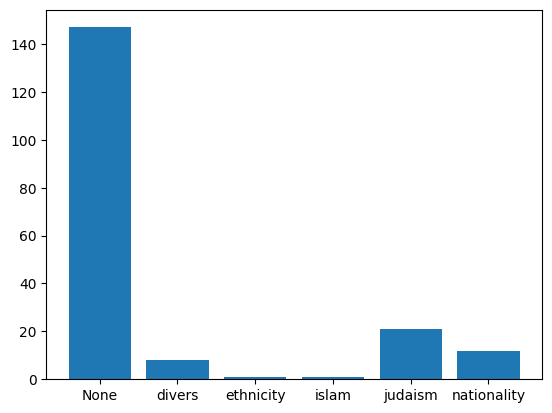

In [160]:
out = concept_cluster(shap_words['1'])
keys, counts = np.unique(out, return_counts=True)

plt.bar(keys, counts)
plt.show()

# T-SNE

In [204]:

# Set a random seed
random_seed = 42
random.seed(random_seed)
 
# Set a random seed for PyTorch (for GPU as well)
torch.manual_seed(random_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(random_seed)

# Load BERT tokenizer and model
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
model = BertModel.from_pretrained('bert-base-uncased')

def embedding(words):
    # The function returns a dictionary containing the token IDs and attention masks
    encoding = tokenizer.batch_encode_plus(
        words,                    # List of input texts
        padding=True,              # Pad to the maximum sequence length
        truncation=True,           # Truncate to the maximum sequence length if necessary
        return_tensors='pt',      # Return PyTorch tensors
        add_special_tokens=True    # Add special tokens CLS and SEP
    )
    
    input_ids = encoding['input_ids']  # Token IDs
    attention_mask = encoding['attention_mask']  # Attention mask

    with torch.no_grad():
        outputs = model(input_ids, attention_mask=attention_mask)
        #print(outputs.last_hidden_state)
        word__embedding = outputs.last_hidden_state.mean(dim=1)  # This contains the embeddings
    return word__embedding

NameError: name 'torch' is not defined

In [40]:
clustered = []
embedded = embedding(shap_words['1'])
word_embedded = [[shap_words['1'][i],embedded[i]] for i in range(len(shap_words['1']))]

while word_embedded != []:
    dim = len(word_embedded)
    example_list = [word_embedded[i][0] for i in range(dim) if cosine_similarity(word_embedded[0][1].reshape(1, -1), word_embedded[i][1].reshape(1, -1))[0][0] >= 0.9]
    word_embedded = [word_embedded[i] for i in range(dim) if word_embedded[i][0] not in example_list]
    clustered.append(example_list)
    #print(clustered)

In [257]:
weighted = np.array([embedding(shap_words['1'])*3, embedding(shap_words['2'])*2, embedding(shap_words['2'])])

In [47]:
flat = [f for cluster in clustered for f in cluster]
tsne= TSNE().fit_transform(np.array(embedding(shap_words['1'])))
tsne_s= TSNE().fit_transform(np.array(embedding(flat)))
#tsne_w = TSNE().fit_transform(weighted)

In [64]:
word_weight = np.array([shap_words['1'],shap_words['2'], shap_words['3']]).flatten()

In [44]:
colors_l = ['blue', 'orange', 'green', 'red', 'b', 'g', 'r', 'c', 'm', 'y', 'k', 'purple', 'brown', 'pink', 'gray']

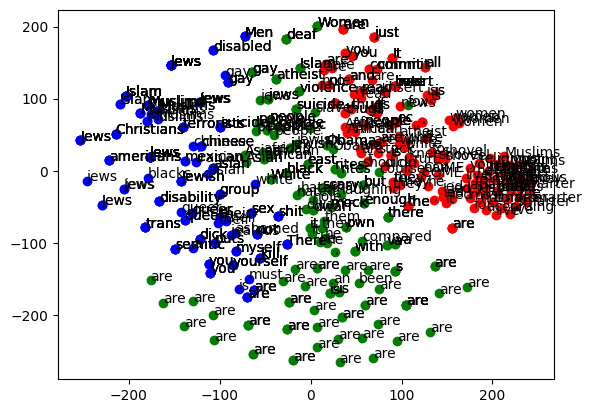

In [68]:
# T-SNE für weighted erste 3 shapley values nicht vorsortiert
color_w = ['b', 'g', 'r']

for i in range(3):
    plt.scatter(tsne_w[190*i:190*(i+1),0], tsne_w[190*i:190*(i+1),1], c = color_w[i])


for i in range(len(tsne_w)):
    plt.text(tsne_w[i,0], tsne_w[i,1], word_weight[i])

C:\Users\lppoh\AppData\Local\Temp\ipykernel_26660\774804814.py:7: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(tsne_s[b:b+e,0], tsne_s[b:b+e,1], c = color)


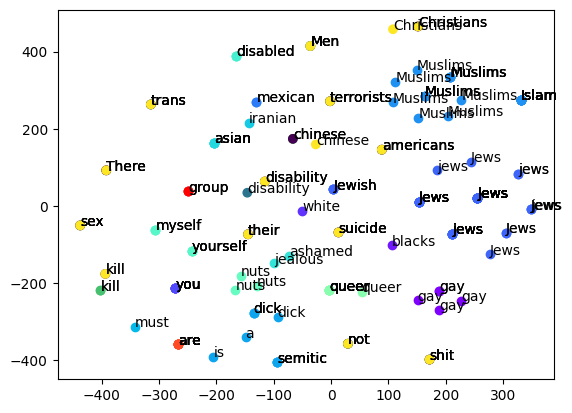

In [339]:
# T-SNE für ersten shapley value nach vorsortieren mit cosine similarity

b = 0
colors = cm.rainbow(np.linspace(0, 1, len(clustered)))
for cluster, color in zip(clustered, colors):
    e = len(cluster)
    plt.scatter(tsne_s[b:b+e,0], tsne_s[b:b+e,1], c = color)
    b = b+e

for i in range(len(tsne)):
    plt.text(tsne_s[i,0], tsne_s[i,1], flat[i])

plt.show()

In [44]:
clustered_tsne = []
words_f = list(np.copy(flat))
while words_f != []:
    example_list = [words_f[i] for i in range(len(words_f)) if abs((tsne_s[0]-tsne_s[i])).sum() <= 65]
    words_f = [words_f[i] for i in range(len(words_f)) if words_f[i] not in example_list]
    clustered_tsne.append(example_list)

In [46]:
len(clustered_tsne)

21

# Gaussian Mixture Model

c:\Users\lppoh\anaconda3\envs\NLP\Lib\site-packages\sklearn\cluster\_kmeans.py:1426: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


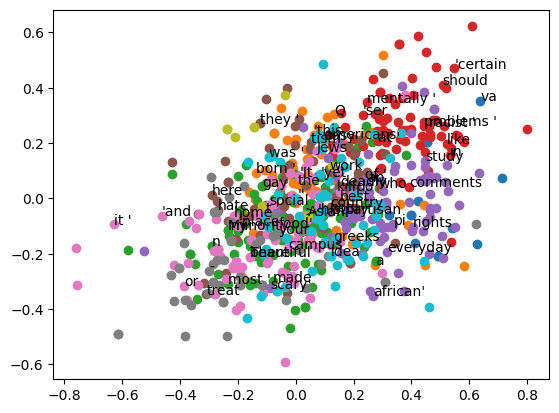

In [337]:
# define dataset
#X = np.array(embedding(shap_words['1']))
X = emb
# define the model
model_gauss = GaussianMixture(n_components=10)
# fit the model
model_gauss.fit(X)
# assign a cluster to each example
yhat = model_gauss.predict(X)
# retrieve unique clusters
clusters = np.unique(yhat)
# create scatter plot for samples from each cluster
for cluster in clusters:
 # get row indexes for samples with this cluster
    row_ix = np.where(yhat == cluster)
 # create scatter of these samples
    plt.scatter(X[row_ix, 0], X[row_ix, 1])
# show the plot

for i in range(0, len(X), 10):
    plt.text(X[i, 0], X[i, 1], safe['tokens'][i])


plt.show()

# Spectral Clustering

c:\Users\lppoh\anaconda3\envs\NLP\Lib\site-packages\sklearn\cluster\_kmeans.py:1426: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\lppoh\anaconda3\envs\NLP\Lib\site-packages\sklearn\cluster\_kmeans.py:1426: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


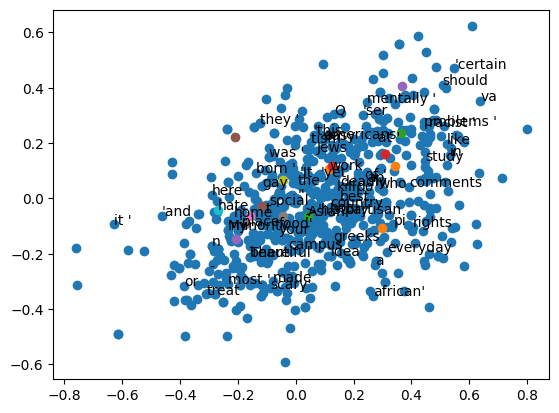

In [353]:
X = emb
# define the model
model_s = SpectralClustering(n_clusters=15)
model_s.fit(X)
ys = model_s.fit_predict(X)
# retrieve unique clusters
clusters = np.unique(ys)
# create scatter plot for samples from each cluster
for cluster in clusters:
 # get row indexes for samples with this cluster
    row_ix = np.where(ys == cluster)
 # create scatter of these samples
    plt.scatter(X[row_ix, 0], X[row_ix, 1])
# show the plot

for i in range(0, len(X), 10):
    plt.text(X[i, 0], X[i, 1], safe['tokens'][i])


plt.show()

In [349]:
y_db

array([  0,   0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,
        12,  13,  14,  15,  16,  17,  18,  19,  11,  20,  21,  22,  23,
        24,  25,  11,  26,  27,  28,  29,  30,  31,  32,  33,  34,  35,
        18,  36,  37,  38,  39,  40,  41,  42,  43,  44,  45,  46,  47,
        15,  48,  49,  42,  50,  51,  52,  53,  54,  55,  56,  57,  58,
        59,  60,  61,  62,  63,  64,  65,  66,  67,  68,  69,  70,  71,
        72,  73,  74,  75,  76,  77,  78,  79,  80,  81,  82,  83,  84,
        85,  86,  87,  88,  89,  90,  91,  44,  92,  93,  94,  95,  96,
        97,  98,  99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109,
       110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120,  11, 121,
       122, 123, 124, 125, 126, 127, 128, 129, 130, 131,   4, 132, 133,
       134, 135, 136, 137, 138, 139, 125,  46, 140, 141, 142, 143, 144,
       145, 146,  94, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156,
       157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 16

In [39]:
for i in zip(yhat, flat):
    print(i)

(7, 'gay')
(2, 'gay')
(2, 'gay')
(10, 'gay')
(1, 'gay')
(1, 'group')
(3, 'group')
(6, 'group')
(2, 'blacks')
(12, 'white')
(4, 'you')
(13, 'you')
(3, 'you')
(12, 'you')
(4, 'yourself')
(1, 'yourself')
(2, 'yourself')
(13, 'yourself')
(6, 'you')
(2, 'you')
(9, 'you')
(2, 'jews')
(10, 'Jews')
(2, 'jews')
(1, 'jealous')
(9, 'jews')
(2, 'jews')
(10, 'jews')
(2, 'jews')
(1, 'Jews')
(9, 'jews')
(2, 'Jews')
(10, 'jews')
(2, 'Jews')
(1, 'jews')
(1, 'Jews')
(6, 'Jewish')
(1, 'jews')
(6, 'Jewish')
(13, 'jews')
(1, 'Jewish')
(6, 'jews')
(1, 'Jewish')
(6, 'jews')
(13, 'jews')
(1, 'Jews')
(6, 'jews')
(1, 'Jews')
(6, 'jews')
(13, 'Jews')
(1, 'jews')
(6, 'Jews')
(1, 'jews')
(6, 'Jews')
(13, 'jews')
(10, 'Jews')
(5, 'jews')
(8, 'Jews')
(2, 'jews')
(1, 'Jews')
(10, 'Jews')
(5, 'Jews')
(8, 'Jews')
(2, 'Jews')
(1, 'Jews')
(10, 'Jews')
(5, 'mexican')
(8, 'Muslims')
(2, 'must')
(1, 'mexican')
(10, 'muslims')
(5, 'myself')
(8, 'myself')
(2, 'myself')
(1, 'Muslims')
(2, 'Muslims')
(11, 'Muslims')
(2, 'Muslim

# Shapley Values weighted

In [128]:
shap_try = pd.read_csv(f'../../output/API_classification/shap/gpt/toxigen/gpt_toxigen.csv', delimiter= ',')
shap_try= shap_try.rename(columns= {'Unnamed: 0': 'ids'})
shap_try = shap_try[:190]

for j in range(190):
    #Bring tokenized into workable format
    t = shap_try['tokenized'][j].replace('\n', '\' \'').replace('"', '\'').split('\' \'')
    shap_try['tokenized'][j]  = [it.strip(' \'').strip('[').strip(']')for it in t]
    shap_try['tokenized'][j] = [it for it in t if it != ""]

    #Bring shap values into workable format
    s = shap_try['shap_values'][j].split(' ')
    s = [i.strip(' \'').strip('[').strip(']').strip('\n') for i in s]
    shap_try['shap_values'][j] = [float(i) for i in s if i != ""]

C:\Users\lppoh\AppData\Local\Temp\ipykernel_26660\2916297676.py:8: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  shap_try['tokenized'][j]  = [it.strip(' \'').strip('[').strip(']')for it in t]
C:\Users\lppoh\AppData\Local\Temp\ipykernel_26660

In [129]:
len(sum(shap_try['shap_values'].values.tolist(), [])), len(sum(shap_try['tokenized'].values.tolist(), []))

(4648, 4644)

In [327]:
token = np.array(sum(shap_try['tokenized'].values.tolist(), []))
value = np.array(sum(shap_try['shap_values'].values.tolist(), []))
uni = np.unique(token, return_counts=True)[0]
safe = []
for i in range(len(uni)):
    ind = np.where(token == uni[i])
    safe.append([uni[i], value[ind].mean()])
    
safe = pd.DataFrame(safe)
safe = safe.rename(columns={0:'tokens', 1:'values'})
safe['tokens'] = [safe['tokens'][i].strip(" ") for i in range(len(safe))]
safe = safe.sort_values(by = 'values')

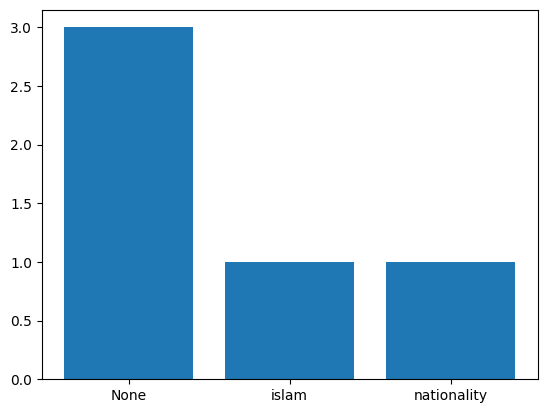

In [263]:
out = concept_cluster(list(safe['tokens'][:5]))
keys, counts = np.unique(out, return_counts=True)

plt.bar(keys, counts)
plt.show()

In [277]:
emb = embedding(safe['tokens'])
weight_tokens = np.zeros((emb.shape[0], emb.shape[1]))
for i in range(emb.shape[0]):
    weight_tokens[i] = emb[i]*safe['values'][i]

In [316]:
safe['values'][:100]

467   -0.780379
149   -0.478773
139   -0.465178
268   -0.463620
420   -0.415992
         ...   
155   -0.090557
685   -0.089941
398   -0.089142
515   -0.086799
587   -0.084452
Name: values, Length: 100, dtype: float64

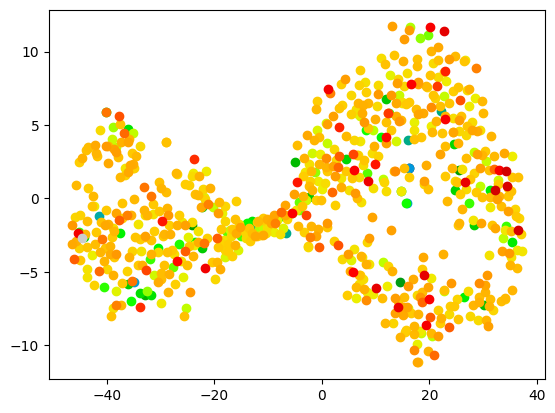

In [343]:
tsne_wt = TSNE().fit_transform(weight_tokens)
s = safe['values']

colors = cm.nipy_spectral((s-min(s))/(max(s)-min(s)))

for t, color in zip(tsne_wt, colors):
    plt.scatter(t[0], t[1], color = color)

#for i in range(len(tsne_wt)):
#    plt.text(tsne_wt[i,0], tsne_wt[i,1], safe['tokens'][i])

plt.show()

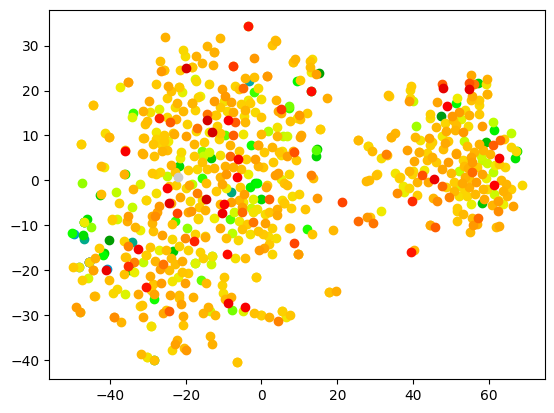

In [325]:
tsne_wt = TSNE().fit_transform(emb)

for t, color in zip(tsne_wt, colors):
    plt.scatter(t[0], t[1], color = color)

In [130]:
for i in range(len(shap_try)):
    if len(shap_try['shap_values'][i]) != len(shap_try['tokenized'][i]):
        print(i)

118
123
128
138
